# 실험 000 — 같은 seed의 모델·증강 비교

한 번 실행해 18개 조합을 순차 학습하고 오답·확신·모델 간 겹침을 분석합니다.
검증 분할은 seed 5로 고정하고 학습 seed는 5·6·7을 사용합니다.
증강 비교는 EfficientNet-B0의 basic·strong·erasing·perspective 네 가지입니다.
erasing과 perspective는 각각 strong+가림, strong+원근을 뜻합니다.
모델 비교는 strong 증강의 EfficientNet-B0·MobileNetV3 Large·ResNet18 Places365입니다.
B0 strong은 두 비교에서 공유하므로 총 18회입니다.

프로젝트 루트의 별도 커널에서 노트북을 저장한 뒤 전체 실행합니다.
epoch별 CSV와 최적 가중치를 기록합니다. 완료한 실행은 설정·원본 데이터·코드·산출물 해시가 일치할 때 재사용합니다.
중단된 실행은 해당 조합부터 처음 학습하고, 이후 분석까지 자동으로 이어집니다.


In [1]:
import csv
import hashlib
import itertools
import json
import os
import random
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from torchvision.transforms import functional as F

BASE_DIR = Path.cwd().resolve()
SPLIT_SEED = 5
RUN_SEEDS = (5, 6, 7)
params = {
	"epoch": 50,
	"early_stopping": True,
	"min_epochs": 5,
	"patience": 5,
	"batch_size": 32,
	"learning_rates": (0.001, 0.0003, 0.0001),
	"valid_ratio": 0.15,
	"workers": 0,
}
CONDITIONS = (
	("efficientnet_b0", "basic"),
	("efficientnet_b0", "strong"),
	("efficientnet_b0", "erasing"),
	("efficientnet_b0", "perspective"),
	("mobilenet_v3_large", "strong"),
	("resnet18_places365", "strong"),
)
AUGMENTATIONS = {
	"basic": {"scale_min": 0.7, "brightness": 0.3, "contrast": 0.3, "saturation": 0.2, "erase_p": 0.0, "perspective_p": 0.0},
	"strong": {"scale_min": 0.5, "brightness": 0.4, "contrast": 0.4, "saturation": 0.3, "erase_p": 0.0, "perspective_p": 0.0},
	"erasing": {"scale_min": 0.5, "brightness": 0.4, "contrast": 0.4, "saturation": 0.3, "erase_p": 0.1, "perspective_p": 0.0},
	"perspective": {"scale_min": 0.5, "brightness": 0.4, "contrast": 0.4, "saturation": 0.3, "erase_p": 0.0, "perspective_p": 0.3},
}
RESULT_DIR = BASE_DIR / "실험결과" / "000_모델증강비교" / f"split_{SPLIT_SEED}"
RUN_DIR = RESULT_DIR / "runs"
CODE_DIR = RESULT_DIR / "코드"
NOTEBOOK_PATH = BASE_DIR / "model_transform_test.ipynb"
PLACES_WEIGHT_PATH = BASE_DIR / "resnet18_places365.pth.tar"
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
assert (BASE_DIR / "train").is_dir(), "프로젝트 루트에서 실행하세요."
assert PLACES_WEIGHT_PATH.is_file(), "Places365 사전학습 가중치가 필요합니다."
assert len(RUN_SEEDS) >= 2
assert len(RUN_SEEDS) == len(set(RUN_SEEDS)), "학습 seed가 중복됐습니다."
assert len(CONDITIONS) == len(set(CONDITIONS))
RUN_DIR.mkdir(parents=True, exist_ok=True)
CODE_DIR.mkdir(exist_ok=True)
print("장치:", device)
print("분할 seed:", SPLIT_SEED, "/ 학습 seed:", RUN_SEEDS)
print("학습 조합 수:", len(CONDITIONS) * len(RUN_SEEDS))
print("결과:", RESULT_DIR)


장치: cuda:0
분할 seed: 5 / 학습 seed: (5, 6, 7)
학습 조합 수: 18
결과: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\000_모델증강비교\split_5


## 고정 분할과 실험 조건

같은 436장 검증 사진에 모든 모델을 평가합니다. 같은 조건의 세 학습 seed는 이 검증셋에 대한 반복 실행입니다.
전체 모델은 원본 비율 보존 256×256 패딩과 동일한 정규화를 사용합니다.
학습·검증 데이터의 파일 내용과 실행 설정을 기록합니다.


In [2]:
def seed_everything(seed):
	random.seed(seed)
	np.random.seed(seed)
	torch.manual_seed(seed)
	torch.cuda.manual_seed_all(seed)
	torch.backends.cudnn.deterministic = True
	torch.backends.cudnn.benchmark = False
	torch.backends.cudnn.allow_tf32 = False
	torch.backends.cuda.matmul.allow_tf32 = False


def file_hash(path):
	digest = hashlib.sha256()
	with Path(path).open("rb") as f:
		for chunk in iter(lambda: f.read(1024 * 1024), b""):
			digest.update(chunk)
	return digest.hexdigest()


def write_csv(path, rows):
	assert rows, f"저장할 행이 없습니다: {path}"
	temporary = Path(str(path) + ".tmp")
	with temporary.open("w", newline="", encoding="utf-8-sig") as f:
		writer = csv.DictWriter(f, fieldnames=list(rows[0]))
		writer.writeheader()
		writer.writerows(rows)
	temporary.replace(path)


def write_json(path, value):
	temporary = Path(str(path) + ".tmp")
	temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8")
	temporary.replace(path)


IMG_SIZE = 256
NORM_MEAN = (0.485, 0.456, 0.406)
NORM_STD = (0.229, 0.224, 0.225)
PAD_FILL = tuple(round(value * 255) for value in NORM_MEAN)


def resize_pad(image):
	width, height = image.size
	scale = IMG_SIZE / max(width, height)
	new_width = max(1, round(width * scale))
	new_height = max(1, round(height * scale))
	image = F.resize(image, [new_height, new_width], antialias=True)
	left = (IMG_SIZE - new_width) // 2
	top = (IMG_SIZE - new_height) // 2
	return F.pad(image, [left, top, IMG_SIZE - new_width - left, IMG_SIZE - new_height - top], fill=PAD_FILL)


class RandomAreaCrop:
	def __init__(self, scale):
		self.scale = scale

	def __call__(self, image):
		top, left, height, width = transforms.RandomResizedCrop.get_params(image, scale=self.scale, ratio=(0.75, 4 / 3))
		return F.crop(image, top, left, height, width)


def build_valid_transform():
	return transforms.Compose([
		transforms.Lambda(resize_pad),
		transforms.ToTensor(),
		transforms.Normalize(NORM_MEAN, NORM_STD),
	])


def build_model(model_name, pretrained=False, places_weight_path=None):
	if model_name == "resnet18_places365":
		net = models.resnet18(weights=None, num_classes=365)
		if pretrained:
			if places_weight_path is None:
				raise ValueError("Places365 사전학습 가중치 경로가 필요합니다.")
			checkpoint = torch.load(places_weight_path, map_location="cpu", weights_only=True)
			state_dict = {key.removeprefix("module."): value for key, value in checkpoint["state_dict"].items()}
			net.load_state_dict(state_dict)
		net.fc = nn.Linear(net.fc.in_features, 1)
	elif model_name == "mobilenet_v3_large":
		weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V1 if pretrained else None
		net = models.mobilenet_v3_large(weights=weights)
		net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, 1)
	elif model_name == "efficientnet_b0":
		weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
		net = models.efficientnet_b0(weights=weights)
		net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, 1)
	else:
		raise ValueError(f"알 수 없는 모델: {model_name}")
	return net


def build_train_transform(augmentation):
	settings = AUGMENTATIONS[augmentation]
	operations = [
		RandomAreaCrop(scale=(settings["scale_min"], 1.0)),
		transforms.RandomHorizontalFlip(p=0.5),
		transforms.ColorJitter(brightness=settings["brightness"], contrast=settings["contrast"], saturation=settings["saturation"]),
	]
	if settings["perspective_p"] > 0:
		operations.append(transforms.RandomPerspective(distortion_scale=0.15, p=settings["perspective_p"], fill=PAD_FILL))
	operations.extend([transforms.Lambda(resize_pad), transforms.ToTensor(), transforms.Normalize(NORM_MEAN, NORM_STD)])
	if settings["erase_p"] > 0:
		operations.append(transforms.RandomErasing(p=settings["erase_p"], scale=(0.02, 0.1), value=0))
	return transforms.Compose(operations)


seed_everything(SPLIT_SEED)
full_valid = datasets.ImageFolder(BASE_DIR / "train", build_valid_transform())
assert full_valid.class_to_idx == {"6e": 0, "it": 1}
labels = [label for _, label in full_valid.samples]
train_idx, valid_idx = train_test_split(list(range(len(labels))), test_size=params["valid_ratio"], stratify=labels, random_state=SPLIT_SEED)
valid_ids = [Path(full_valid.samples[i][0]).stem for i in valid_idx]
valid_labels = np.array([labels[i] for i in valid_idx], dtype=np.int64)
assert len(valid_ids) == len(set(valid_ids)), "검증 ID가 중복됐습니다."
valid_loader = DataLoader(Subset(full_valid, valid_idx), batch_size=params["batch_size"], shuffle=False, num_workers=0)
image_manifest = [{"path": str(Path(path).relative_to(BASE_DIR)), "label": label, "sha256": file_hash(path)} for path, label in full_valid.samples]
dataset_hash = hashlib.sha256(json.dumps(image_manifest, sort_keys=True).encode()).hexdigest()
saved_notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
training_cell_ids = {"data-models", "training"}
training_source = "".join("".join(c["source"]) for c in saved_notebook["cells"] if c["id"] in training_cell_ids)
training_hash = hashlib.sha256(training_source.encode()).hexdigest()
base_config = {
	"split_seed": SPLIT_SEED,
	"params": params,
	"image_size": IMG_SIZE,
	"normalization_mean": NORM_MEAN,
	"normalization_std": NORM_STD,
	"pad_fill": PAD_FILL,
	"dataset_sha256": dataset_hash,
	"training_source_sha256": training_hash,
	"places_weight_sha256": file_hash(PLACES_WEIGHT_PATH),
	"torch": str(torch.__version__),
	"torchvision": str(torchvision.__version__),
	"device_type": device.type,
	"tf32": False,
}
# 저장된 JSON과 비교할 수 있도록 튜플을 리스트로 통일합니다.
base_config = json.loads(json.dumps(base_config))
write_csv(RESULT_DIR / "validation_split.csv", [{"id": i, "label": int(y)} for i, y in zip(valid_ids, valid_labels)])
write_json(RESULT_DIR / "dataset_manifest.json", image_manifest)
shutil.copy2(NOTEBOOK_PATH, CODE_DIR / f"model_transform_test_{training_hash[:12]}.ipynb")
print(f"학습 {len(train_idx)}장 / 검증 {len(valid_idx)}장")


학습 2470장 / 검증 436장


## 학습과 완료 결과 재사용

전체 최저 검증 BCE 가중치를 선택하고, 검증 확률 분석에서는 대회와 같은 1e-6 클리핑 Log Loss를 계산합니다.
각 학습률 단계는 최소 5 epoch 이후 연속 5회 미개선이면 전환하며 마지막 단계에서 종료합니다.
완료 표시는 가중치·epoch 기록·예측·학습 곡선이 모두 저장된 뒤 기록합니다.
설정이나 완료 산출물이 바뀌면 명시적으로 오류를 표시합니다.


In [3]:
def run_epoch(model, loader, criterion, optimizer=None):
	"""optimizer가 주어지면 학습, 아니면 평가. (평균 loss, 정확도)를 반환."""
	training = optimizer is not None
	model.train() if training else model.eval()

	total_loss, total_correct, total_n = 0.0, 0, 0
	with torch.set_grad_enabled(training):
		for inputs, targets in loader:
			inputs = inputs.to(device)
			targets = targets.float().unsqueeze(1).to(device)  # (B,) -> (B,1)

			logits = model(inputs)
			loss = criterion(logits, targets)
			assert torch.isfinite(loss), "학습 또는 검증 손실이 유한하지 않습니다."

			if training:
				optimizer.zero_grad()
				loss.backward()
				optimizer.step()

			probs = torch.sigmoid(logits)
			preds = (probs >= 0.5).float()
			total_loss += loss.item() * inputs.size(0)
			total_correct += (preds == targets).sum().item()
			total_n += inputs.size(0)

	return total_loss / total_n, total_correct / total_n


def train_model(model, dataloaders, criterion, optimizer, num_epochs, epoch_csv, early_stopping, min_epochs, patience, learning_rates, checkpoint_path):
	assert min_epochs > 0
	assert patience > 0
	assert len(learning_rates) > 0
	assert all(rate > 0 for rate in learning_rates)
	since = time.time()
	history = {'train_loss': [], 'train_acc': [], 'valid_loss': [], 'valid_acc': []}
	best_acc, best_loss, best_epoch = -float('inf'), float('inf'), -1
	stage_index, stage_epochs = 0, 0
	stage_best_loss = float('inf')
	epochs_without_improvement = 0
	epoch_writer = csv.writer(epoch_csv)
	epoch_writer.writerow(('epoch', 'learning_rate', 'lr_stage', 'stage_epoch', 'train_loss', 'train_acc', 'valid_loss', 'valid_acc'))

	for epoch in range(1, num_epochs + 1):
		learning_rate = learning_rates[stage_index]
		for group in optimizer.param_groups:
			group['lr'] = learning_rate
		stage_epochs += 1
		tr_loss, tr_acc = run_epoch(model, dataloaders['train'], criterion, optimizer)
		va_loss, va_acc = run_epoch(model, dataloaders['valid'], criterion)

		history['train_loss'].append(tr_loss)
		history['train_acc'].append(tr_acc)
		history['valid_loss'].append(va_loss)
		history['valid_acc'].append(va_acc)
		epoch_writer.writerow((epoch, learning_rate, stage_index + 1, stage_epochs, tr_loss, tr_acc, va_loss, va_acc))
		epoch_csv.flush()
		print(f'Epoch {epoch}/{num_epochs} | lr {learning_rate:g} | train loss {tr_loss:.4f}, acc {tr_acc:.3f} | valid loss {va_loss:.4f}, acc {va_acc:.3f}')

		if (va_loss < best_loss) or ((va_loss == best_loss) and (va_acc > best_acc)):
			best_acc, best_loss, best_epoch = va_acc, va_loss, epoch
			torch.save(model.state_dict(), checkpoint_path)
			print(f'  ↳ best Log Loss 갱신! {checkpoint_path} 저장')

		if va_loss < stage_best_loss:
			stage_best_loss = va_loss
			epochs_without_improvement = 0
		elif stage_epochs > min_epochs:
			epochs_without_improvement += 1

		if epochs_without_improvement >= patience:
			if stage_index + 1 < len(learning_rates):
				stage_index += 1
				stage_epochs = 0
				stage_best_loss = float('inf')
				epochs_without_improvement = 0
				print(f'다음 epoch부터 학습률 {learning_rates[stage_index]:g} 적용')
			elif early_stopping:
				print(f'조기 종료: epoch {epoch}, 마지막 학습률에서 Log Loss {patience}회 연속 미개선')
				break

	elapsed = time.time() - since
	print(f'\n학습 완료 ({elapsed // 60:.0f}분 {elapsed % 60:.0f}초)')
	print(f'best: epoch {best_epoch}, valid acc {best_acc:.4f}, log loss {best_loss:.4f}')
	return history, best_epoch, best_loss


def evaluate_model(model):
	model.eval()
	probabilities = []
	with torch.inference_mode():
		for inputs, _ in valid_loader:
			probabilities.append(torch.sigmoid(model(inputs.to(device))).squeeze(1).cpu().numpy())
	p = np.concatenate(probabilities).astype(np.float64)
	assert len(p) == len(valid_ids)
	assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
	true_p = np.where(valid_labels == 1, p, 1 - p)
	losses = -np.log(np.clip(true_p, 1e-6, 1 - 1e-6))
	errors = (p >= 0.5) != valid_labels.astype(bool)
	rows = [
		{"id": image_id, "label": int(y), "prob": float(prob), "correct_probability": float(correct_p), "confidence": float(max(prob, 1 - prob)), "is_error": int(error), "log_loss": float(loss)}
		for image_id, y, prob, correct_p, error, loss in zip(valid_ids, valid_labels, p, true_p, errors, losses)
	]
	metrics = {
		"samples": len(p), "errors": int(errors.sum()),
		"error_rate": float(errors.mean()), "accuracy": float(1 - errors.mean()),
		"log_loss": float(losses.mean()),
		"wrong_loss_contribution": float(losses[errors].sum() / len(p)),
		"wrong_mean_confidence": float(np.maximum(p[errors], 1 - p[errors]).mean()) if errors.any() else None,
		"confident_wrong_90": int((errors & (np.maximum(p, 1 - p) >= 0.9)).sum()),
	}
	return rows, metrics


def execute_run(model_name, augmentation, seed):
	assert json.loads(json.dumps(params)) == base_config["params"], "설정이 변경됐습니다. 데이터·설정 셀부터 다시 실행하세요."
	run_id = f"{model_name}_{augmentation}_seed{seed}"
	directory = RUN_DIR / run_id
	directory.mkdir(exist_ok=True)
	config = dict(base_config, model=model_name, augmentation=augmentation, augmentation_settings=AUGMENTATIONS[augmentation], seed=seed)
	completion_path = directory / "completed.json"
	artifacts = ("checkpoint.pt", "epochs.csv", "validation_predictions.csv", "metrics.json", "learning_curve.png")
	if completion_path.exists():
		completion = json.loads(completion_path.read_text(encoding="utf-8"))
		assert completion["config"] == config, f"완료 실행의 설정이 다릅니다: {run_id}"
		assert set(completion["artifact_sha256"]) == set(artifacts)
		for filename, digest in completion["artifact_sha256"].items():
			assert (directory / filename).is_file() and file_hash(directory / filename) == digest, f"완료 산출물이 달라졌습니다: {run_id}/{filename}"
		with (directory / "validation_predictions.csv").open(newline="", encoding="utf-8-sig") as f:
			rows = list(csv.DictReader(f))
		assert [r["id"] for r in rows] == valid_ids
		assert [int(r["label"]) for r in rows] == valid_labels.tolist()
		metrics = json.loads((directory / "metrics.json").read_text(encoding="utf-8"))
		print("완료 결과 재사용:", run_id, flush=True)
		return metrics, rows
	write_json(directory / "config.json", config)
	seed_everything(seed)
	model = build_model(model_name, pretrained=True, places_weight_path=PLACES_WEIGHT_PATH).to(device)
	seed_everything(seed)
	full_train = datasets.ImageFolder(BASE_DIR / "train", build_train_transform(augmentation))
	assert full_train.samples == full_valid.samples
	loaders = {
		"train": DataLoader(Subset(full_train, train_idx), batch_size=params["batch_size"], shuffle=True, num_workers=0, generator=torch.Generator().manual_seed(seed)),
		"valid": DataLoader(Subset(full_valid, valid_idx), batch_size=params["batch_size"], shuffle=False, num_workers=0, generator=torch.Generator().manual_seed(seed)),
	}
	optimizer = torch.optim.Adam(model.parameters(), lr=params["learning_rates"][0])
	checkpoint_path = directory / "checkpoint.pt"
	print(f"\n모델 {model_name} / 증강 {augmentation} / seed {seed}", flush=True)
	started = time.perf_counter()
	try:
		with (directory / "epochs.csv").open("w", newline="", encoding="utf-8-sig") as epoch_csv:
			history, best_epoch, best_loss = train_model(model, loaders, nn.BCEWithLogitsLoss(), optimizer, num_epochs=params["epoch"], epoch_csv=epoch_csv, early_stopping=params["early_stopping"], min_epochs=params["min_epochs"], patience=params["patience"], learning_rates=params["learning_rates"], checkpoint_path=checkpoint_path)
		seconds = time.perf_counter() - started
		assert best_epoch > 0, "최적 가중치가 선택되지 않았습니다."
		model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
		rows, metrics = evaluate_model(model)
		metrics = dict(run_id=run_id, model=model_name, augmentation=augmentation, seed=seed, split_seed=SPLIT_SEED, best_epoch=best_epoch, best_valid_loss=best_loss, epochs_run=len(history["train_loss"]), seconds=seconds, n_params=sum(p.numel() for p in model.parameters()), **metrics)
		write_csv(directory / "validation_predictions.csv", rows)
		write_json(directory / "metrics.json", metrics)
		fig, axes = plt.subplots(1, 2, figsize=(11, 4))
		epochs = range(1, len(history["train_loss"]) + 1)
		for ax, metric in zip(axes, ("loss", "acc")):
			ax.plot(epochs, history[f"train_{metric}"], label="train")
			ax.plot(epochs, history[f"valid_{metric}"], label="valid")
			ax.scatter(best_epoch, history[f"valid_{metric}"][best_epoch - 1], color="red", label="selected")
			ax.set_xlabel("Epoch")
			ax.set_ylabel(metric)
			ax.legend()
			ax.grid(alpha=0.3)
		fig.suptitle(run_id)
		fig.tight_layout()
		fig.savefig(directory / "learning_curve.png", dpi=140)
		plt.close(fig)
		write_json(completion_path, {"config": config, "artifact_sha256": {name: file_hash(directory / name) for name in artifacts}})
		return metrics, rows
	finally:
		del model, optimizer, loaders
		if device.type == "cuda":
			torch.cuda.empty_cache()


## 18개 조합 순차 실행

학습 seed별로 B0의 네 증강과 MobileNet·ResNet strong을 실행합니다.
완료된 결과는 즉시 통합 runs.csv에 반영합니다. 완료된 각 실행의 검증 예측은 메모리에 모아 다음 분석에서 공유합니다.


In [4]:
results = []
predictions = {}
for seed in RUN_SEEDS:
	for model_name, augmentation in CONDITIONS:
		metrics, rows = execute_run(model_name, augmentation, seed)
		results.append(metrics)
		predictions[metrics["run_id"]] = rows
		write_csv(RESULT_DIR / "runs.csv", results)
assert len(results) == len(CONDITIONS) * len(RUN_SEEDS)
print("완료 실행 수:", len(results))



모델 efficientnet_b0 / 증강 basic / seed 5
Epoch 1/50 | lr 0.001 | train loss 0.2121, acc 0.916 | valid loss 0.1101, acc 0.959
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\000_모델증강비교\split_5\runs\efficientnet_b0_basic_seed5\checkpoint.pt 저장
Epoch 2/50 | lr 0.001 | train loss 0.1119, acc 0.957 | valid loss 0.0892, acc 0.970
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\000_모델증강비교\split_5\runs\efficientnet_b0_basic_seed5\checkpoint.pt 저장
Epoch 3/50 | lr 0.001 | train loss 0.0913, acc 0.968 | valid loss 0.0510, acc 0.979
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\000_모델증강비교\split_5\runs\efficientnet_b0_basic_seed5\checkpoint.pt 저장
Epoch 4/50 | lr 0.001 | train loss 0.0651, acc 0.976 | valid loss 0.0413, acc 0.989
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\000_모델증강비교\split_5\runs\efficientnet_b0_basic_seed5\checkpoint.pt 저장
Epoch 5/50 | lr 0.001 | train loss 0.0681, acc 0.976 | valid los

## 오답·확신·겹침 분석

같은 seed의 증강 쌍과 모델 쌍을 비교하고, 같은 조건의 seed 쌍도 비교합니다.
pairwise.csv의 a_only_errors는 A가 틀리고 B가 맞힌 사진 수, b_only_errors는 B가 새로 틀린 사진 수입니다.
Jaccard는 공통 오답 수를 두 모델의 오답 합집합 수로 나눈 값입니다. 둘 다 오답이 없으면 빈칸으로 표시합니다.
confidence 변화는 A의 오답에서 정답 확률이 B에서 얼마나 달라졌는지 기록합니다.
두 비교 그룹의 전원 일치 오답과 기존 조건부 temperature 앙상블 지표도 기록합니다.


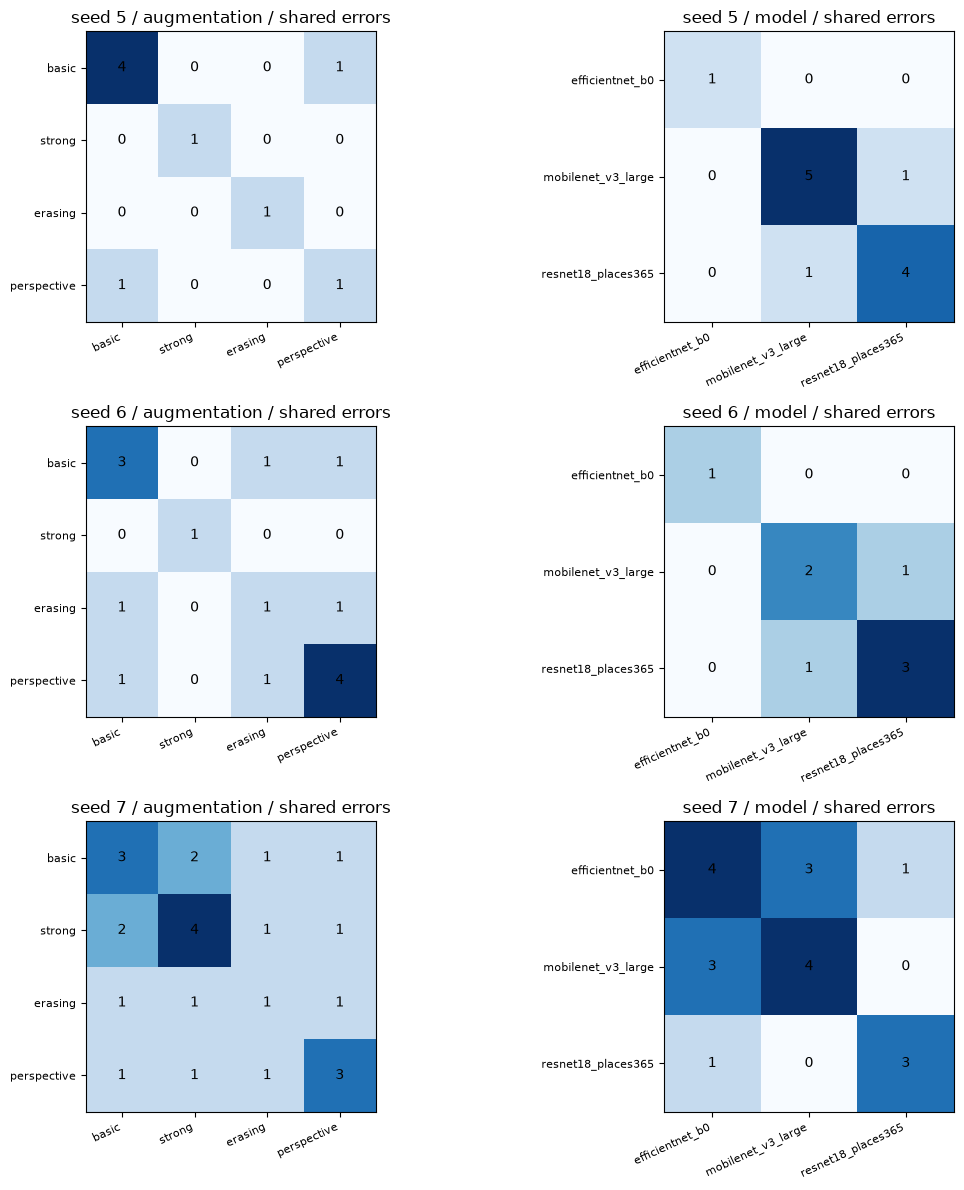

조건별 요약: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\000_모델증강비교\split_5\summary.csv
쌍별 비교: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\000_모델증강비교\split_5\pairwise.csv
전원 일치 분석: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\000_모델증강비교\split_5\group_agreement.csv
분석 보고서: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\000_모델증강비교\split_5\분석결과.md


In [5]:
def prediction_arrays(run_id):
	rows = predictions[run_id]
	assert [r["id"] for r in rows] == valid_ids
	assert [int(r["label"]) for r in rows] == valid_labels.tolist()
	p = np.array([float(r["prob"]) for r in rows])
	assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
	true_p = np.where(valid_labels == 1, p, 1 - p)
	error = (p >= 0.5) != valid_labels.astype(bool)
	loss = -np.log(np.clip(true_p, 1e-6, 1 - 1e-6))
	return p, true_p, error, loss


def compare_pair(run_a, run_b, category):
	a, true_a, wrong_a, loss_a = prediction_arrays(run_a)
	b, true_b, wrong_b, loss_b = prediction_arrays(run_b)
	union = wrong_a | wrong_b
	return {
		"comparison": category, "run_a": run_a, "run_b": run_b,
		"errors_a": int(wrong_a.sum()), "errors_b": int(wrong_b.sum()),
		"shared_errors": int((wrong_a & wrong_b).sum()),
		"a_only_errors": int((wrong_a & ~wrong_b).sum()),
		"b_only_errors": int((wrong_b & ~wrong_a).sum()),
		"union_errors": int(union.sum()),
		"error_jaccard": float((wrong_a & wrong_b).sum() / union.sum()) if union.any() else None,
		"class_disagreements": int(((a >= 0.5) != (b >= 0.5)).sum()),
		"log_loss_a": float(loss_a.mean()), "log_loss_b": float(loss_b.mean()),
		"mean_loss_change_b_minus_a": float((loss_b - loss_a).mean()),
		"a_errors_true_probability_a": float(true_a[wrong_a].mean()) if wrong_a.any() else None,
		"a_errors_true_probability_b": float(true_b[wrong_a].mean()) if wrong_a.any() else None,
		"a_errors_probability_improved": int((wrong_a & (true_b > true_a)).sum()),
		"a_errors_probability_decreased": int((wrong_a & (true_b < true_a)).sum()),
		"a_errors_loss_change_b_minus_a": float((loss_b[wrong_a] - loss_a[wrong_a]).sum() / len(valid_ids)),
	}


def analyze_results():
	metadata = {row["run_id"]: row for row in results}
	assert set(metadata) == set(predictions)
	pairs = []
	for seed in RUN_SEEDS:
		augmentation_runs = [r["run_id"] for r in results if (r["seed"] == seed) and (r["model"] == "efficientnet_b0")]
		model_runs = [r["run_id"] for r in results if (r["seed"] == seed) and (r["augmentation"] == "strong")]
		for category, run_ids in (("augmentation", augmentation_runs), ("model", model_runs)):
			for a, b in itertools.combinations(run_ids, 2):
				pairs.append(compare_pair(a, b, category))
	for model_name, augmentation in CONDITIONS:
		run_ids = [r["run_id"] for r in results if (r["model"] == model_name) and (r["augmentation"] == augmentation)]
		for a, b in itertools.combinations(run_ids, 2):
			pairs.append(compare_pair(a, b, "seed"))
	write_csv(RESULT_DIR / "pairwise.csv", pairs)
	summary = []
	for model_name, augmentation in CONDITIONS:
		rows = [r for r in results if (r["model"] == model_name) and (r["augmentation"] == augmentation)]
		assert len(rows) == len(RUN_SEEDS)
		summary.append({
			"model": model_name, "augmentation": augmentation, "runs": len(rows),
			"error_count_mean": float(np.mean([r["errors"] for r in rows])),
			"error_rate_mean": float(np.mean([r["error_rate"] for r in rows])),
			"log_loss_mean": float(np.mean([r["log_loss"] for r in rows])),
			"log_loss_std": float(np.std([r["log_loss"] for r in rows], ddof=1)),
		})
	write_csv(RESULT_DIR / "summary.csv", summary)
	group_rows = []
	long_predictions = []
	for row in results:
		for prediction in predictions[row["run_id"]]:
			long_predictions.append(dict(run_id=row["run_id"], model=row["model"], augmentation=row["augmentation"], seed=row["seed"], **prediction))
	write_csv(RESULT_DIR / "all_validation_predictions.csv", long_predictions)
	fig, axes = plt.subplots(len(RUN_SEEDS), 2, figsize=(12, 4 * len(RUN_SEEDS)), squeeze=False)
	for row_index, seed in enumerate(RUN_SEEDS):
		for column, category in enumerate(("augmentation", "model")):
			group = [r for r in results if (r["seed"] == seed) and ((r["model"] == "efficientnet_b0") if category == "augmentation" else (r["augmentation"] == "strong"))]
			probs = np.column_stack([prediction_arrays(r["run_id"])[0] for r in group])
			wrong = np.column_stack([prediction_arrays(r["run_id"])[2] for r in group])
			overlap = wrong.astype(int).T @ wrong.astype(int)
			ax = axes[row_index, column]
			ax.imshow(overlap, cmap="Blues", vmin=0, vmax=max(1, int(overlap.max())))
			tick_labels = [r["augmentation"] if category == "augmentation" else r["model"] for r in group]
			ax.set_xticks(range(len(group)), tick_labels, rotation=25, ha="right", fontsize=8)
			ax.set_yticks(range(len(group)), tick_labels, fontsize=8)
			ax.set_title(f"seed {seed} / {category} / shared errors")
			for i in range(len(group)):
				for j in range(len(group)):
					ax.text(j, i, str(overlap[i, j]), ha="center", va="center")
			votes = (probs >= 0.5).sum(axis=1)
			unanimous = (votes == 0) | (votes == len(group))
			assert len(group) in (3, 4)
			middle = np.sort(probs, axis=1)[:, 1:-1].mean(axis=1)
			combined = np.where(unanimous, probs.mean(axis=1), middle)
			temperature = np.where(unanimous, 0.3, 0.7)
			calibrated = torch.sigmoid(torch.logit(torch.from_numpy(combined)) / torch.from_numpy(temperature)).numpy()
			group_wrong = (calibrated >= 0.5) != valid_labels.astype(bool)
			true_p = np.where(valid_labels == 1, calibrated, 1 - calibrated)
			loss = -np.log(np.clip(true_p, 1e-6, 1 - 1e-6))
			group_rows.append({
				"group": category, "seed": seed, "members": len(group),
				"union_member_errors": int(wrong.any(axis=1).sum()),
				"all_members_wrong": int(wrong.all(axis=1).sum()),
				"unanimous_samples": int(unanimous.sum()),
				"unanimous_wrong": int((unanimous & group_wrong).sum()),
				"ensemble_errors": int(group_wrong.sum()), "ensemble_error_rate": float(group_wrong.mean()),
				"ensemble_log_loss": float(loss.mean()),
				"unanimous_wrong_loss_contribution": float(loss[unanimous & group_wrong].sum() / len(valid_ids)),
			})
	fig.tight_layout()
	fig.savefig(RESULT_DIR / "error_overlap.png", dpi=150)
	plt.show()
	plt.close(fig)
	write_csv(RESULT_DIR / "group_agreement.csv", group_rows)
	report = [
		"# 실험 000 분석 결과", "",
		f"검증 분할 seed {SPLIT_SEED}, 검증 {len(valid_ids)}장, 학습 seed {list(RUN_SEEDS)}, 완료 {len(results)}회.", "",
		"같은 검증셋의 세 학습 seed를 비교했다. 표준편차는 해당 조건의 실행 변동이며 새 데이터의 오차범위를 뜻하지 않는다.", "",
		"## 조건별 요약", "",
		"| 모델 | 증강 | 평균 오답 수 | 평균 Log Loss | 표본 표준편차 |",
		"|---|---|---:|---:|---:|",
	]
	for r in summary:
		report.append(f"| {r['model']} | {r['augmentation']} | {r['error_count_mean']:.2f} | {r['log_loss_mean']:.6f} | {r['log_loss_std']:.6f} |")
	report.extend(["", "## 같은 seed의 쌍별 오답", "", "| 비교 | A | B | A 오답 | B 오답 | 공통 | A만 오답 | B만 오답 |", "|---|---|---|---:|---:|---:|---:|---:|"])
	for r in pairs:
		if r["comparison"] in ("augmentation", "model"):
			report.append(f"| {r['comparison']} | {r['run_a']} | {r['run_b']} | {r['errors_a']} | {r['errors_b']} | {r['shared_errors']} | {r['a_only_errors']} | {r['b_only_errors']} |")
	report.extend(["", "## 전원 일치 오답과 앙상블", "", "| 비교 | seed | 전원 일치 오답 | 앙상블 오답 | Log Loss |", "|---|---:|---:|---:|---:|"])
	for r in group_rows:
		report.append(f"| {r['group']} | {r['seed']} | {r['unanimous_wrong']} | {r['ensemble_errors']} | {r['ensemble_log_loss']:.6f} |")
	report.extend(["", "공통 오답이 0이어도 한쪽 모델의 오답 자체가 0이면 다양성에 대한 근거가 제한된다.", "", "오답 확신 변화와 같은 조건의 seed별 비교는 [pairwise.csv](pairwise.csv)에 기록했다.", "", "![공통 오답 수](error_overlap.png)", ""])
	(RESULT_DIR / "분석결과.md").write_text("\n".join(report), encoding="utf-8")
	print("조건별 요약:", RESULT_DIR / "summary.csv")
	print("쌍별 비교:", RESULT_DIR / "pairwise.csv")
	print("전원 일치 분석:", RESULT_DIR / "group_agreement.csv")
	print("분석 보고서:", RESULT_DIR / "분석결과.md")
	return summary, pairs, group_rows


summary, pairs, group_rows = analyze_results()


## 제출 CSV — B0 strong·가림·원근, 서로 다른 seed, 조건부 T0.3 TTA

기존 학습을 마친 커널에서 아래 셀만 실행합니다. 18회 학습 셀은 다시 실행할 필요가 없습니다.
새 커널이면 설정 셀과 고정 분할·모델 정의 셀을 먼저 실행한 뒤 이 셀을 실행합니다.
기본 구성은 strong seed 5·strong+가림 seed 6·strong+원근 seed 7입니다. 구성은 SUBMISSION_MEMBERS에서 변경합니다.
모델별 원본·좌우 반전 확률을 평균한 뒤 전원 일치이면 평균·T=0.3, 불일치이면 가운데 확률·T=0.7을 적용합니다.
TTA 전후 검증 오답·Log Loss와 저장된 개별 검증 예측의 재현 차이를 출력하고, 테스트 500장의 제출 CSV와 가중치 출처 JSON을 split_5/submissions/에 저장합니다.
같은 이름의 기존 CSV와 예측이 다르면 오류를 내고 기존 CSV를 보존합니다.


In [ ]:
SUBMISSION_MEMBERS = (("strong", 5), ("erasing", 6), ("perspective", 7))
assert len(SUBMISSION_MEMBERS) == 3
assert {augmentation for augmentation, seed in SUBMISSION_MEMBERS} == {"strong", "erasing", "perspective"}
assert RESULT_DIR == BASE_DIR / "실험결과" / "000_모델증강비교" / "split_5"
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

with (RESULT_DIR / "validation_split.csv").open(newline="", encoding="utf-8-sig") as f:
	submission_valid_rows = list(csv.DictReader(f))
submission_valid_ids = [row["id"] for row in submission_valid_rows]
submission_labels = np.array([int(row["label"]) for row in submission_valid_rows])
submission_valid_paths = [BASE_DIR / "train" / ("it" if int(row["label"]) == 1 else "6e") / (row["id"] + ".jpg") for row in submission_valid_rows]
submission_models = nn.ModuleList()
submission_sources = []
submission_saved_probs = []
for augmentation, seed in SUBMISSION_MEMBERS:
	run_id = f"efficientnet_b0_{augmentation}_seed{seed}"
	directory = RUN_DIR / run_id
	completion = json.loads((directory / "completed.json").read_text(encoding="utf-8"))
	config = completion["config"]
	assert (config["model"] == "efficientnet_b0") and (config["augmentation"] == augmentation) and (config["seed"] == seed) and (config["split_seed"] == 5)
	assert all(config[key] == base_config[key] for key in base_config), f"학습 설정이 다릅니다: {run_id}"
	checkpoint_path = directory / "checkpoint.pt"
	checkpoint_hash = file_hash(checkpoint_path)
	assert checkpoint_hash == completion["artifact_sha256"]["checkpoint.pt"], f"가중치가 변경됐습니다: {run_id}"
	assert file_hash(directory / "validation_predictions.csv") == completion["artifact_sha256"]["validation_predictions.csv"]
	with (directory / "validation_predictions.csv").open(newline="", encoding="utf-8-sig") as f:
		saved_rows = list(csv.DictReader(f))
	assert [row["id"] for row in saved_rows] == submission_valid_ids
	assert [int(row["label"]) for row in saved_rows] == submission_labels.tolist()
	submission_saved_probs.append([float(row["prob"]) for row in saved_rows])
	net = build_model("efficientnet_b0")
	net.load_state_dict(torch.load(checkpoint_path, map_location="cpu", weights_only=True))
	submission_models.append(net)
	submission_sources.append({"run_id": run_id, "checkpoint": str(checkpoint_path.relative_to(BASE_DIR)), "sha256": checkpoint_hash})
submission_models.to(device).eval()
submission_n_params = sum(parameter.numel() for parameter in submission_models.parameters())
assert submission_n_params <= 20_000_000
submission_transform = build_valid_transform()
print("제출 구성:", SUBMISSION_MEMBERS, "/ 장치:", device, "/ 파라미터:", f"{submission_n_params:,}", flush=True)


def submission_predict(paths):
	base_batches, tta_batches = [], []
	with torch.inference_mode():
		for start in range(0, len(paths), 32):
			images = []
			for path in paths[start:start + 32]:
				with Image.open(path) as image:
					images.append(submission_transform(image.convert("RGB")))
			inputs = torch.stack(images).to(device)
			base_probs = torch.cat([torch.sigmoid(net(inputs)) for net in submission_models], dim=1)
			flipped_probs = torch.cat([torch.sigmoid(net(inputs.flip(dims=[3]))) for net in submission_models], dim=1)
			base_batches.append(base_probs.cpu().numpy())
			tta_batches.append(((base_probs + flipped_probs) / 2).cpu().numpy())
	return np.concatenate(base_batches).astype(np.float64), np.concatenate(tta_batches).astype(np.float64)


def submission_combine(member_probs):
	assert (member_probs.ndim == 2) and (member_probs.shape[1] == 3)
	assert np.isfinite(member_probs).all() and ((member_probs >= 0) & (member_probs <= 1)).all()
	votes = member_probs >= 0.5
	unanimous = (votes == votes[:, :1]).all(axis=1)
	combined = np.where(unanimous, member_probs.mean(axis=1), np.median(member_probs, axis=1))
	temperature = np.where(unanimous, 0.3, 0.7)
	return torch.sigmoid(torch.logit(torch.from_numpy(combined)) / torch.from_numpy(temperature)).numpy()


submission_valid_base, submission_valid_tta = submission_predict(submission_valid_paths)
submission_reproduction_diff = float(np.abs(submission_valid_base - np.array(submission_saved_probs).T).max())
assert submission_reproduction_diff <= 0.00001, f"저장된 검증 예측이 재현되지 않습니다: {submission_reproduction_diff}"
submission_valid_base_probs = submission_combine(submission_valid_base)
submission_valid_tta_probs = submission_combine(submission_valid_tta)
submission_valid_metrics = {}
for rule, probabilities in (("T0.3", submission_valid_base_probs), ("T0.3_TTA", submission_valid_tta_probs)):
	true_probs = np.where(submission_labels == 1, probabilities, 1 - probabilities)
	submission_valid_metrics[rule] = {"samples": len(probabilities), "errors": int(((probabilities >= 0.5) != submission_labels.astype(bool)).sum()), "log_loss": float(-np.log(np.clip(true_probs, 1e-6, 1 - 1e-6)).mean())}
	print("검증", rule, submission_valid_metrics[rule], flush=True)
print("저장된 개별 검증 확률과 최대 차이:", submission_reproduction_diff, flush=True)

submission_test_paths = sorted((BASE_DIR / "test").glob("*.jpg"))
submission_test_ids = [path.stem for path in submission_test_paths]
with (BASE_DIR / "sample_submission.csv").open(newline="", encoding="utf-8-sig") as f:
	submission_expected_ids = [row["id"] for row in csv.DictReader(f)]
assert len(submission_test_ids) == len(set(submission_test_ids)) == len(submission_expected_ids) == 500
assert set(submission_test_ids) == set(submission_expected_ids)
_, submission_test_tta = submission_predict(submission_test_paths)
submission_test_probs = submission_combine(submission_test_tta)
assert np.isfinite(submission_test_probs).all() and ((submission_test_probs >= 0) & (submission_test_probs <= 1)).all()
submission_rows = [{"id": image_id, "prob": f"{probability:.6f}"} for image_id, probability in zip(submission_test_ids, submission_test_probs)]
submission_output_dir = RESULT_DIR / "submissions"
submission_output_dir.mkdir(exist_ok=True)
submission_tag = "_".join(f"{augmentation}{seed}" for augmentation, seed in SUBMISSION_MEMBERS)
submission_path = submission_output_dir / f"submission_{submission_tag}_T0.3_TTA.csv"
if submission_path.exists():
	with submission_path.open(newline="", encoding="utf-8-sig") as f:
		assert list(csv.DictReader(f)) == submission_rows, "같은 이름의 기존 CSV와 예측이 다릅니다. 기존 파일을 보존하고 새 이름을 사용하세요."
else:
	write_csv(submission_path, submission_rows)
write_json(submission_path.with_suffix(".json"), {
	"members": submission_sources, "split_seed": 5, "image_size": IMG_SIZE, "parameters": submission_n_params,
	"tta": "각 모델의 원본·좌우 반전 sigmoid 확률 평균 후 앙상블",
	"combination": "전원 일치: 세 확률 평균, 불일치: 가운데 확률",
	"temperature": {"unanimous": 0.3, "disagreement": 0.7}, "tf32": False,
	"validation": submission_valid_metrics, "validation_reproduction_max_difference": submission_reproduction_diff,
	"csv_sha256": file_hash(submission_path), "device": str(device),
})
del submission_models
if device.type == "cuda":
	torch.cuda.empty_cache()
print("제출 CSV:", submission_path.resolve(), "/ 500장", flush=True)
